
--- Top 10 Eigenvalues (Growth Rates) ---
  Mode 1: (-4.748575099737522+3.2675897953370537e-12j)
  Mode 2: (-11.20761699895249-1.8507951426863927e-11j)
  Mode 3: (-15.181763738798+301.43202310324216j)
  Mode 4: (-15.18176373896346-301.4320231029334j)
  Mode 5: (-18.729738148151352+434.3477776899214j)
  Mode 6: (-18.729738149587245-434.3477776898261j)
  Mode 7: (-21.25311633862431+1.5871038564918402e-11j)
  Mode 8: (-23.87018288857715-697.2631860377805j)
  Mode 9: (-23.870182888685992+697.2631860383084j)
  Mode 10: (-27.854716988863633-1.8193132015392847e-13j)

Max Growth Rate: -4.74858
Status: STABLE


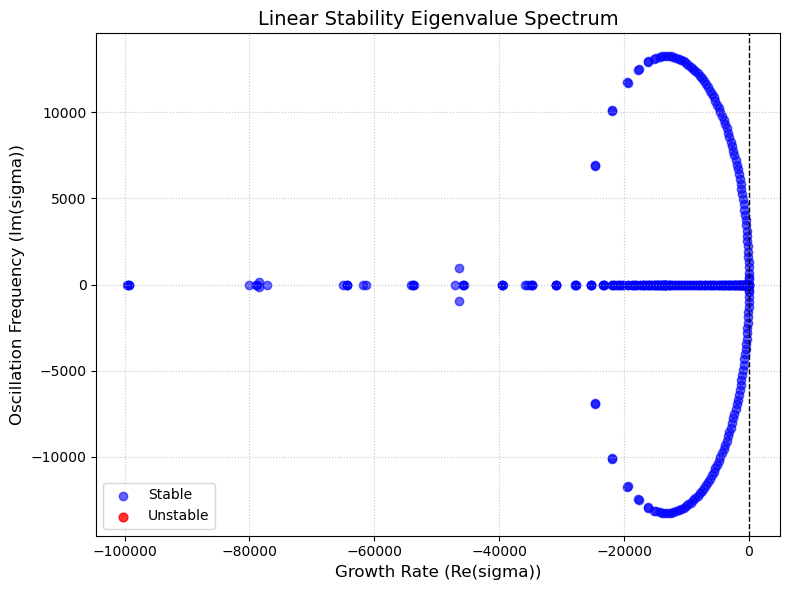

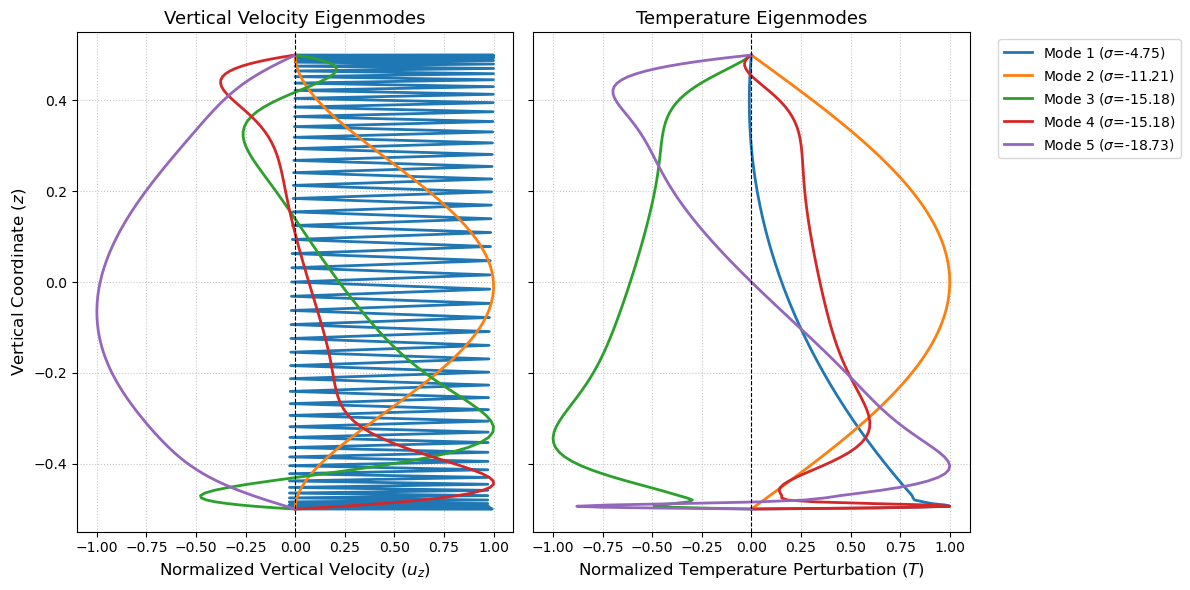

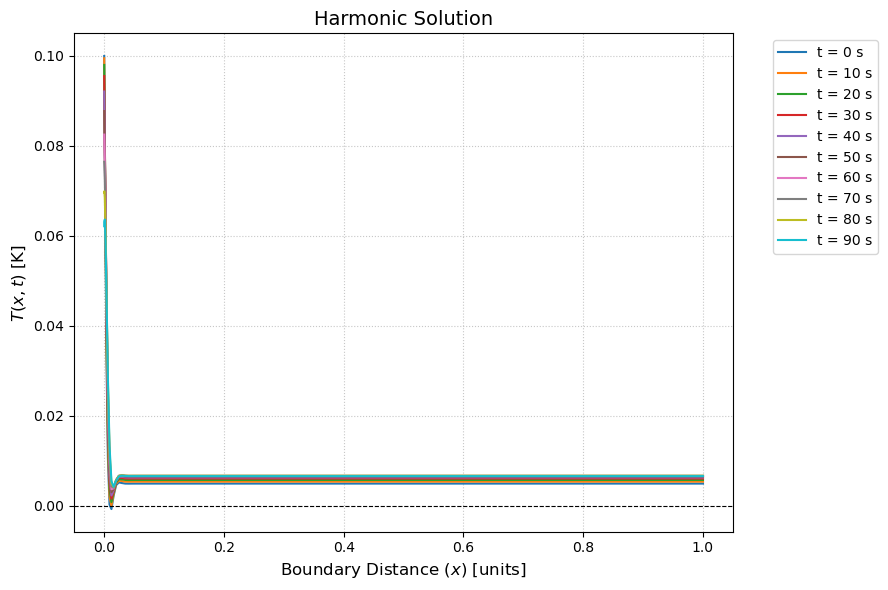

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import eig

#####################################################
# INVERSION REGIME
#####################################################

def create_chebyshev_grid(N):
  """Generates Chebyshev-Lobatto nodes on [-1, 1]."""
  j = np.arange(N + 1)
  z = np.cos(np.pi * j / N)
  return z


def get_derivatives(N):
  """Computes 1st and 2nd Chebyshev differentiation matrices,
  scaled to physical interval [-1/2, 1/2] via the chain rule.
  """
  # 1. Standard computational grid on [-1, 1]
  j = np.arange(N + 1)
  xi = np.cos(np.pi * j / N)

  c = np.ones(N + 1)
  c[0] = 2.0
  c[N] = 2.0
  c = c * (-1) ** j

  X = np.outer(xi, np.ones(N + 1))
  dX = X - X.T
  D1_comp = np.outer(c, 1.0 / c) / (dX + np.eye(N + 1))
  D1_comp = D1_comp - np.diag(np.sum(D1_comp.T, axis=0))
  D2_comp = np.dot(D1_comp, D1_comp)

  # 2. Map to physical domain z in [-1/2, 1/2] and scale via chain rule
  z = 0.5 * xi
  D1 = 2.0 * D1_comp  
  D2 = 4.0 * D2_comp

  return z, D1, D2

def analytic_model_temp_profile(z, t, A_T, omega, kappa, mu):
  """Computes the real-valued background temperature profile from analytic model"""

  theta_B = - np.arctan(1.0 / (1.0 + mu))
  theta_A = np.arctan(mu / (2.0 + mu))

  x = z + 1/2

  alpha_term = np.sqrt(omega / (2.0 * kappa))

  # Term 1: Exponentially decaying thermal wave component
  coeff_1 = (A_T * np.sqrt((2.0 + mu) ** 2 + mu**2) / ((1.0 + mu) ** 2 + 1.0))
  phase_1 = theta_A - alpha_term * x + omega * t
  term_1 = (coeff_1* np.exp(-alpha_term * x) * (np.cos(phase_1) + 1j * np.sin(phase_1)))

  # Term 2: Oscillating uniform PE component
  coeff_2 = A_T * mu / np.sqrt((1.0 + mu) ** 2 + 1.0)
  phase_2 = theta_B + omega * t
  term_2 = coeff_2 * (np.cos(phase_2) + 1j * np.sin(phase_2))

  T_complex = term_1 + term_2
    
  return np.real(T_complex)

def analytic_model_pressure_profile(z, t, alpha_p, alpha_T, A_T, omega, kappa, mu, tau_D, gamma):
  """Computes the exact analytical background pressure"""

  theta_B = - np.arctan(1.0 / (1.0 + mu))
  theta_A = np.arctan(mu / (2.0 + mu))

  amplitude = A_T * gamma * (alpha_p / alpha_T) * np.sqrt(2.0 / (omega * tau_D)) / np.sqrt((1.0 + mu) ** 2 + 1.0)
  phase = theta_B + omega * t
  p_complex = amplitude * (np.cos(phase) + 1j * np.sin(phase))

  return np.real(p_complex)


def build_system_matrix(N, Pr, Ra_th, kx, D_val, alpha_b, drho_dT, drho_dp, cp_b, a, t, A_T, omega, kappa, mu):
    """Assembles the 4-variable system: [u_x, u_z, p, T]"""
    z, D1, D2 = get_derivatives(N)
    n_pts = N + 1
    dim = 4 * n_pts  # Fields: u_x (0), u_z (1), p (2), T (3)
    
    A = np.zeros((dim, dim), dtype=complex)
    B = np.zeros((dim, dim), dtype=complex)
    
    I = np.eye(n_pts)
    
    # Placeholder background states
    alpha_p, alpha_T = 1,1
    Tb = analytic_model_temp_profile(z, t, A_T, omega, kappa, mu)
    p_b_scalar = analytic_model_pressure_profile(z, t, alpha_p, alpha_T, A_T, omega, kappa, mu, tau_D=1.0, gamma=1)
    rho_b = 1.0 + drho_dT * (Tb - np.mean(Tb)) + drho_dp * p_b_scalar * np.ones_like(z)
    
    drho_dz = D1 @ rho_b
    dp_dz = -rho_b
    dTb_dz = D1 @ Tb
    dp_dz = -rho_b
    
    # --- Block Slices ---
    ux_slice = slice(0, n_pts)
    uz_slice = slice(n_pts, 2 * n_pts)
    p_slice = slice(2 * n_pts, 3 * n_pts)
    T_slice = slice(3 * n_pts, 4 * n_pts)
    
    # --- Row 1: Eq. (5.5) + (5.9) [Continuity / Density disturbance] ---
    B[ux_slice, p_slice] = drho_dp * I
    B[ux_slice, T_slice] = drho_dT * I
    
    A[ux_slice, ux_slice] = -1j * kx * np.diag(rho_b)
    A[ux_slice, uz_slice] = -np.diag(rho_b) @ D1 - np.diag(drho_dz)
    
    # --- Row 2: Eq. (5.6) [u_x Momentum] ---
    B[uz_slice, ux_slice] = Pr ** (-1) * np.diag(rho_b)
    
    A[uz_slice, ux_slice] = D2 - (4.0 / 3.0) * (kx**2) * I
    A[uz_slice, uz_slice] = (1j * kx / 3.0) * D1
    A[uz_slice, p_slice] = -Ra_th * 1j * kx * I
    
    # --- Row 3: Eq. (5.7) + (5.9) [u_z Momentum] ---
    B[p_slice, uz_slice] = Pr ** (-1) * np.diag(rho_b)
    
    A[p_slice, ux_slice] = (1j * kx / 3.0) * D1
    A[p_slice, uz_slice] = (4.0 / 3.0) * D2 - (kx**2) * I
    A[p_slice, p_slice] = -Ra_th * D1 - Ra_th * drho_dp * I
    A[p_slice, T_slice] = -Ra_th * drho_dT * I
    
    # --- Row 4: Eq. (5.8) [Energy Equation] ---
    B[T_slice, p_slice] = -D_val * alpha_b * np.diag(Tb)
    B[T_slice, T_slice] = np.diag(rho_b * cp_b)
    
    A[T_slice, uz_slice] = np.diag(
        -rho_b * cp_b * dTb_dz + D_val * alpha_b * Tb * dp_dz
    )
    A[T_slice, T_slice] = D2 - (kx**2) * I
    
    # --- Boundary Conditions (Dirichlet: u_x=0, u_z=0, T=0 at walls) ---
    for b_idx in [0, N]:
        for field_base in [0, n_pts, 3 * n_pts]:
            row = b_idx + field_base
            A[row, :] = 0
            B[row, :] = 0
            A[row, row] = 1.0
    
    return A, B


def solve_stability(A, B):
  """Solves the generalized eigenvalue problem and returns filtered modes."""
  eigenvalues, eigenvectors = eig(A, B)

  # Filter out extreme numerical artifacts
  valid = np.isfinite(eigenvalues) & (np.abs(eigenvalues) < 1e5)
  filtered_eigs = eigenvalues[valid]
  filtered_evecs = eigenvectors[:, valid]

  return filtered_eigs, filtered_evecs


def plot_spectrum(eigenvalues):
  """Plots the complex eigenvalue spectrum."""
  plt.figure(figsize=(8, 6))

  real_parts = np.real(eigenvalues)
  imag_parts = np.imag(eigenvalues)

  unstable = real_parts > 0
  stable = ~unstable

  plt.scatter(
      real_parts[stable],
      imag_parts[stable],
      color="blue",
      alpha=0.6,
      label="Stable",
  )
  plt.scatter(
      real_parts[unstable],
      imag_parts[unstable],
      color="red",
      alpha=0.8,
      s=40,
      label="Unstable",
  )

  plt.axvline(x=0, color="black", linestyle="--", linewidth=1)
  plt.xlabel("Growth Rate (Re(sigma))", fontsize=12)
  plt.ylabel("Oscillation Frequency (Im(sigma))", fontsize=12)
  plt.title("Linear Stability Eigenvalue Spectrum", fontsize=14)
  plt.grid(True, linestyle=":", alpha=0.7)
  plt.legend(loc="lower left")
  plt.tight_layout()


def plot_top_eigenmodes(z, eigenvectors, eigenvalues, n_pts, top_k=5):
  """Plots spatial structures for vertical velocity (uz) and temperature (T)."""
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

  sorted_idx = np.argsort(np.real(eigenvalues))[::-1]

  for i in range(min(top_k, len(sorted_idx))):
    idx = sorted_idx[i]
    val = eigenvalues[idx]

    # Extract slices for uz and T using variable-grouped layout
    uz_profile = np.real(eigenvectors[n_pts : 2 * n_pts, idx])
    T_profile = np.real(eigenvectors[3 * n_pts : 4 * n_pts, idx])

    # Normalize amplitudes for clean comparison
    if np.max(np.abs(uz_profile)) > 0:
      uz_profile /= np.max(np.abs(uz_profile))
    if np.max(np.abs(T_profile)) > 0:
      T_profile /= np.max(np.abs(T_profile))

    label_str = f"Mode {i+1} ($\sigma$={val.real:.2f})"

    # Plot Vertical Velocity
    ax1.plot(uz_profile, z, linewidth=2, label=label_str)
    # Plot Temperature
    ax2.plot(T_profile, z, linewidth=2, label=label_str)

  # Format Subplot 1 (uz)
  ax1.axvline(x=0, color="black", linestyle="--", linewidth=0.8)
  ax1.set_ylabel("Vertical Coordinate ($z$)", fontsize=12)
  ax1.set_xlabel("Normalized Vertical Velocity ($u_z$)", fontsize=12)
  ax1.set_title("Vertical Velocity Eigenmodes", fontsize=13)
  ax1.grid(True, linestyle=":", alpha=0.7)

  # Format Subplot 2 (T)
  ax2.axvline(x=0, color="black", linestyle="--", linewidth=0.8)
  ax2.set_xlabel("Normalized Temperature Perturbation ($T$)", fontsize=12)
  ax2.set_title("Temperature Eigenmodes", fontsize=13)
  ax2.grid(True, linestyle=":", alpha=0.7)
  ax2.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

  plt.tight_layout()

def plot_analytical_temperature_profile(z, t, A_T, omega, kappa, mu):
  plt.figure(figsize=(9, 6))
    
  x = z - np.min(z)

  # Times matching your reference plot style
  times = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]

  for ti in times:
    Tb = analytic_model_temp_profile(z, ti, A_T, omega, kappa, mu)
    plt.plot(x, Tb, linewidth=1.5, label=f"t = {ti} s")

  plt.axhline(y=0, color="black", linestyle="--", linewidth=0.8)
  plt.xlabel("Boundary Distance ($x$) [units]", fontsize=12)
  plt.ylabel("$T(x,t)$ [K]", fontsize=12)
  plt.title("Harmonic Solution", fontsize=14)
  plt.grid(True, linestyle=":", alpha=0.7)
  plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
  plt.tight_layout()

def main():
    N = 100
    Pr = 1.0
    Ra_th = 1e4
    kx = 3.117
    D_val = 0.1
    alpha_b = 1.0
    drho_dT = -1.0
    drho_dp = 1.0
    cp_b = 1.0
    a = 0.5
    t = 10
    A_T = 0.1
    omega = 0.01
    kappa = 1e-7
    mu = 0.1

    # Get grid and matrices
    z, _, _ = get_derivatives(N)
    n_pts = N + 1

    A, B = build_system_matrix(
        N, Pr, Ra_th, kx, D_val, alpha_b, drho_dT, drho_dp, cp_b, a,
        t, A_T, omega, kappa, mu
    )
    eigenvalues, eigenvectors = solve_stability(A, B)

    # Sort by real part descending
    sorted_idx = np.argsort(np.real(eigenvalues))[::-1]
    sorted_sigma = eigenvalues[sorted_idx]

    print(f"\n--- Top 10 Eigenvalues (Growth Rates) ---")
    for i in range(min(10, len(sorted_sigma))):
        print(f"  Mode {i+1}: {sorted_sigma[i]}")

    max_sigma = np.real(sorted_sigma[0]) if len(sorted_sigma) > 0 else 0.0
    print(f"\nMax Growth Rate: {max_sigma:.5f}")
    print("Status: UNSTABLE" if max_sigma > 0 else "Status: STABLE")

    # Generate visual outputs
    plot_spectrum(eigenvalues)
    plot_top_eigenmodes(z, eigenvectors, eigenvalues, n_pts, top_k=5)
    plt.show()

    plot_analytical_temperature_profile(z, t, A_T, omega, kappa, mu)
    plt.show()


if __name__ == "__main__":
  main()


--- Top 10 Eigenvalues (Growth Rates) ---
  Mode 1: (14.024853126156817-1.0590174308950286e-11j)
  Mode 2: (-8.331787695460248+6.352966815729549e-13j)
  Mode 3: (-25.96317387535476-312.78526155100724j)
  Mode 4: (-25.963173875447335+312.7852615510811j)
  Mode 5: (-33.013864057072105+450.0202161084663j)
  Mode 6: (-33.01386405808716-450.0202161082083j)
  Mode 7: (-36.17229902215994+7.831349742379774e-08j)
  Mode 8: (-46.31931583459718+726.6487305010297j)
  Mode 9: (-46.31931584663736-726.6487305014176j)
  Mode 10: (-67.73652962851332+5.970852607060441e-08j)

Max Growth Rate: 14.02485
Status: UNSTABLE


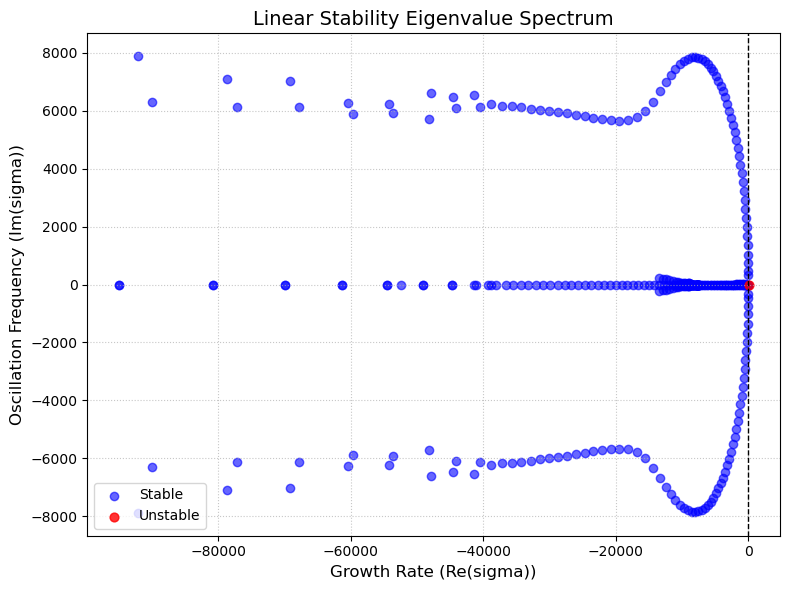

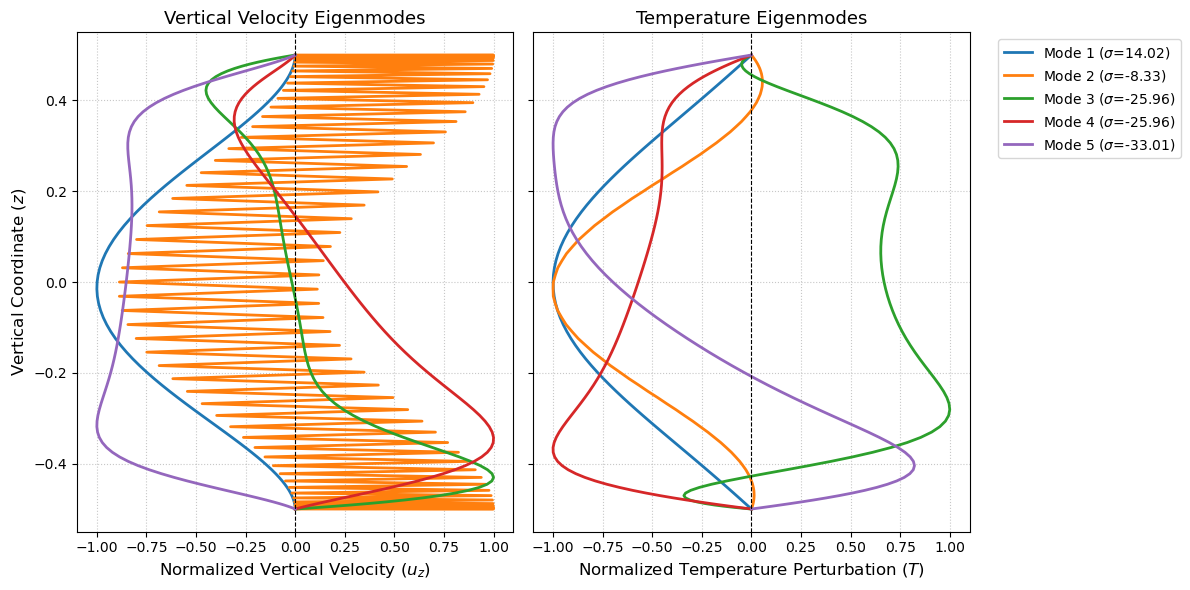

In [58]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import eig

#####################################################
# CONVECTION REGIME
#####################################################

def create_chebyshev_grid(N):
  """Generates Chebyshev-Lobatto nodes on [-1, 1]."""
  j = np.arange(N + 1)
  z = np.cos(np.pi * j / N)
  return z


def get_derivatives(N):
  """Computes 1st and 2nd Chebyshev differentiation matrices,
  scaled to physical interval [-1/2, 1/2] via the chain rule.
  """
  # 1. Standard computational grid on [-1, 1]
  j = np.arange(N + 1)
  xi = np.cos(np.pi * j / N)

  c = np.ones(N + 1)
  c[0] = 2.0
  c[N] = 2.0
  c = c * (-1) ** j

  X = np.outer(xi, np.ones(N + 1))
  dX = X - X.T
  D1_comp = np.outer(c, 1.0 / c) / (dX + np.eye(N + 1))
  D1_comp = D1_comp - np.diag(np.sum(D1_comp.T, axis=0))
  D2_comp = np.dot(D1_comp, D1_comp)

  # 2. Map to physical domain z in [-1/2, 1/2] and scale via chain rule
  z = 0.5 * xi
  D1 = 2.0 * D1_comp  
  D2 = 4.0 * D2_comp

  return z, D1, D2


def build_system_matrix(N, Pr, Ra_th, kx, D_val, alpha_b, drho_dT, drho_dp, cp_b, a):
    """Assembles the 4-variable system: [u_x, u_z, p, T]"""
    z, D1, D2 = get_derivatives(N)
    n_pts = N + 1
    dim = 4 * n_pts  # Fields: u_x (0), u_z (1), p (2), T (3)
    
    A = np.zeros((dim, dim), dtype=complex)
    B = np.zeros((dim, dim), dtype=complex)
    
    I = np.eye(n_pts)
    
    # Placeholder background states
    rho_b = np.ones_like(z)
    drho_dz = np.zeros_like(z)
    Tb = 1.0 - a * z  #Convection regime
    dTb_dz = -a * np.ones_like(z)
    dp_dz = -rho_b
    
    # --- Block Slices ---
    ux_slice = slice(0, n_pts)
    uz_slice = slice(n_pts, 2 * n_pts)
    p_slice = slice(2 * n_pts, 3 * n_pts)
    T_slice = slice(3 * n_pts, 4 * n_pts)
    
    # --- Row 1: Eq. (5.5) + (5.9) [Continuity / Density disturbance] ---
    B[ux_slice, p_slice] = drho_dp * I
    B[ux_slice, T_slice] = drho_dT * I
    
    A[ux_slice, ux_slice] = -1j * kx * np.diag(rho_b)
    A[ux_slice, uz_slice] = -np.diag(rho_b) @ D1 - np.diag(drho_dz)
    
    # --- Row 2: Eq. (5.6) [u_x Momentum] ---
    B[uz_slice, ux_slice] = Pr ** (-1) * np.diag(rho_b)
    
    A[uz_slice, ux_slice] = D2 - (4.0 / 3.0) * (kx**2) * I
    A[uz_slice, uz_slice] = (1j * kx / 3.0) * D1
    A[uz_slice, p_slice] = -Ra_th * 1j * kx * I
    
    # --- Row 3: Eq. (5.7) + (5.9) [u_z Momentum] ---
    B[p_slice, uz_slice] = Pr ** (-1) * np.diag(rho_b)
    
    A[p_slice, ux_slice] = (1j * kx / 3.0) * D1
    A[p_slice, uz_slice] = (4.0 / 3.0) * D2 - (kx**2) * I
    A[p_slice, p_slice] = -Ra_th * D1 - Ra_th * drho_dp * I
    A[p_slice, T_slice] = -Ra_th * drho_dT * I
    
    # --- Row 4: Eq. (5.8) [Energy Equation] ---
    B[T_slice, p_slice] = -D_val * alpha_b * np.diag(Tb)
    B[T_slice, T_slice] = np.diag(rho_b * cp_b)
    
    A[T_slice, uz_slice] = np.diag(
        -rho_b * cp_b * dTb_dz + D_val * alpha_b * Tb * dp_dz
    )
    A[T_slice, T_slice] = D2 - (kx**2) * I
    
    # --- Boundary Conditions (Dirichlet: u_x=0, u_z=0, T=0 at walls) ---
    for b_idx in [0, N]:
        for field_base in [0, n_pts, 3 * n_pts]:
            row = b_idx + field_base
            A[row, :] = 0
            B[row, :] = 0
            A[row, row] = 1.0
    
    return A, B


def solve_stability(A, B):
  """Solves the generalized eigenvalue problem and returns filtered modes."""
  eigenvalues, eigenvectors = eig(A, B)

  # Filter out extreme numerical artifacts
  valid = np.isfinite(eigenvalues) & (np.abs(eigenvalues) < 1e5)
  filtered_eigs = eigenvalues[valid]
  filtered_evecs = eigenvectors[:, valid]

  return filtered_eigs, filtered_evecs


def plot_spectrum(eigenvalues):
  """Plots the complex eigenvalue spectrum."""
  plt.figure(figsize=(8, 6))

  real_parts = np.real(eigenvalues)
  imag_parts = np.imag(eigenvalues)

  unstable = real_parts > 0
  stable = ~unstable

  plt.scatter(
      real_parts[stable],
      imag_parts[stable],
      color="blue",
      alpha=0.6,
      label="Stable",
  )
  plt.scatter(
      real_parts[unstable],
      imag_parts[unstable],
      color="red",
      alpha=0.8,
      s=40,
      label="Unstable",
  )

  plt.axvline(x=0, color="black", linestyle="--", linewidth=1)
  plt.xlabel("Growth Rate (Re(sigma))", fontsize=12)
  plt.ylabel("Oscillation Frequency (Im(sigma))", fontsize=12)
  plt.title("Linear Stability Eigenvalue Spectrum", fontsize=14)
  plt.grid(True, linestyle=":", alpha=0.7)
  plt.legend(loc="lower left")
  plt.tight_layout()


def plot_top_eigenmodes(z, eigenvectors, eigenvalues, n_pts, top_k=5):
  """Plots spatial structures for vertical velocity (uz) and temperature (T)."""
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

  sorted_idx = np.argsort(np.real(eigenvalues))[::-1]

  for i in range(min(top_k, len(sorted_idx))):
    idx = sorted_idx[i]
    val = eigenvalues[idx]

    # Extract slices for uz and T using variable-grouped layout
    uz_profile = np.real(eigenvectors[n_pts : 2 * n_pts, idx])
    T_profile = np.real(eigenvectors[3 * n_pts : 4 * n_pts, idx])

    # Normalize amplitudes for clean comparison
    if np.max(np.abs(uz_profile)) > 0:
      uz_profile /= np.max(np.abs(uz_profile))
    if np.max(np.abs(T_profile)) > 0:
      T_profile /= np.max(np.abs(T_profile))

    label_str = f"Mode {i+1} ($\sigma$={val.real:.2f})"

    # Plot Vertical Velocity
    ax1.plot(uz_profile, z, linewidth=2, label=label_str)
    # Plot Temperature
    ax2.plot(T_profile, z, linewidth=2, label=label_str)

  # Format Subplot 1 (uz)
  ax1.axvline(x=0, color="black", linestyle="--", linewidth=0.8)
  ax1.set_ylabel("Vertical Coordinate ($z$)", fontsize=12)
  ax1.set_xlabel("Normalized Vertical Velocity ($u_z$)", fontsize=12)
  ax1.set_title("Vertical Velocity Eigenmodes", fontsize=13)
  ax1.grid(True, linestyle=":", alpha=0.7)

  # Format Subplot 2 (T)
  ax2.axvline(x=0, color="black", linestyle="--", linewidth=0.8)
  ax2.set_xlabel("Normalized Temperature Perturbation ($T$)", fontsize=12)
  ax2.set_title("Temperature Eigenmodes", fontsize=13)
  ax2.grid(True, linestyle=":", alpha=0.7)
  ax2.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

  plt.tight_layout()

def main():
  N = 100
  Pr = 1.0
  Ra_th = 1e4
  kx = 3.117
  D_val = 0.1
  alpha_b = 1.0
  drho_dT = -1.0
  drho_dp = 1.0
  cp_b = 1.0
  a = 0.5

  # Get grid and matrices
  z, _, _ = get_derivatives(N)
  n_pts = N + 1

  A, B = build_system_matrix(
      N, Pr, Ra_th, kx, D_val, alpha_b, drho_dT, drho_dp, cp_b, a
  )
  eigenvalues, eigenvectors = solve_stability(A, B)

  # Sort by real part descending
  sorted_idx = np.argsort(np.real(eigenvalues))[::-1]
  sorted_sigma = eigenvalues[sorted_idx]

  print(f"\n--- Top 10 Eigenvalues (Growth Rates) ---")
  for i in range(min(10, len(sorted_sigma))):
    print(f"  Mode {i+1}: {sorted_sigma[i]}")

  max_sigma = np.real(sorted_sigma[0]) if len(sorted_sigma) > 0 else 0.0
  print(f"\nMax Growth Rate: {max_sigma:.5f}")
  print("Status: UNSTABLE" if max_sigma > 0 else "Status: STABLE")

  # Generate visual outputs
  plot_spectrum(eigenvalues)
  plot_top_eigenmodes(z, eigenvectors, eigenvalues, n_pts, top_k=5)
  plt.show()


if __name__ == "__main__":
  main()